# 03 — Modelagem e Avaliação

Este notebook realiza o treinamento e a avaliação dos modelos de aprendizado de máquina utilizados para classificar a direção do Ibovespa cinco pregões à frente.

Modelos avaliados:
- Baseline Majority
- Baseline Persistence
- Regressão Logística
- Árvore de Decisão
- Random Forest

A divisão dos dados respeita a ordem cronológica da série temporal, evitando vazamento de informações futuras.

In [2]:
import sys
from pathlib import Path
# Caminho da raiz do projeto
raiz_projeto = Path.cwd().parent
# Adiciona a raiz do projeto ao caminho de importação
sys.path.append(str(raiz_projeto))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import export_text
from sklearn.tree import plot_tree
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, RandomizedSearchCV

from src.modelos import (
    criar_logistic_regression,
    criar_decision_tree,
    criar_random_forest
)

from src.avaliacao import (
    avaliar_modelo
)

from src.depuracao import (
    depurar_modelo
)

In [3]:
# Caminho do dataset processado
arquivo_dataset = Path("../data/processed/ibovespa_features.csv")

# Carregar dados
df = pd.read_csv(
    arquivo_dataset,
    parse_dates=["Date"]
)

print("Dimensões: ", df.shape)

display(df.head())

Dimensões:  (3950, 9)


,Date,Retorno_Diario,Retorno_5d,Retorno_10d,Media_Retorno_5d,Volatilidade_5d,Variacao_Intradiaria,Amplitude_Diaria,Direcao_Futura
0,2010-01-18,0.613239,-1.465222,-0.919409,-0.292293,0.787222,0.605946,1.108969,0
1,2010-01-19,0.731978,-0.238313,-0.471241,-0.044524,0.890929,0.739236,1.697475,0
2,2010-01-20,-2.444607,-3.104355,-3.575620,-0.621636,1.326126,-2.433442,3.486513,0
3,2010-01-21,-2.829912,-5.058667,-5.934621,-1.021674,1.663390,-2.829912,3.730529,0
4,2010-01-22,-0.075449,-3.998376,-5.754095,-0.800950,1.709857,-0.066401,1.856521,1


In [4]:
print("### Validação do dataset ###")

print("\nDimensões:", df.shape)

print("\nPeríodo:")
print("Inicial:", df["Date"].min())
print("Final:", df["Date"].max())

print("\nValores ausentes:")
print(df.isna().sum())

print("\nValores infinitos:")
print(
    np.isinf(
        df.select_dtypes(include="number")
    ).sum()
)

print("\nDistribuição do target:")
print(
    df["Direcao_Futura"]
    .map({0: "QUEDA", 1: "ALTA"})
    .value_counts()
)

### Validação do dataset ###

Dimensões: (3950, 9)

Período:
Inicial: 2010-01-18 00:00:00
Final: 2025-12-19 00:00:00

Valores ausentes:
Date                    0
Retorno_Diario          0
Retorno_5d              0
Retorno_10d             0
Media_Retorno_5d        0
Volatilidade_5d         0
Variacao_Intradiaria    0
Amplitude_Diaria        0
Direcao_Futura          0
dtype: int64

Valores infinitos:
Retorno_Diario          0
Retorno_5d              0
Retorno_10d             0
Media_Retorno_5d        0
Volatilidade_5d         0
Variacao_Intradiaria    0
Amplitude_Diaria        0
Direcao_Futura          0
dtype: int64

Distribuição do target:
Direcao_Futura
ALTA     2082
QUEDA    1868
Name: count, dtype: int64


In [5]:
# Definição das features e target que o modelo usará pra aprender e pra prever

features = [
    "Retorno_Diario",
    "Retorno_5d",
    "Retorno_10d",
    "Media_Retorno_5d",
    "Volatilidade_5d",
    "Variacao_Intradiaria",
    "Amplitude_Diaria",
]

target = "Direcao_Futura"

X = df[features].copy()
y = df[target].copy()

print("Features:")
print(features)

print("\nDimensão de X:", X.shape)
print("\nDimensão de y:", y.shape)

Features:
['Retorno_Diario', 'Retorno_5d', 'Retorno_10d', 'Media_Retorno_5d', 'Volatilidade_5d', 'Variacao_Intradiaria', 'Amplitude_Diaria']

Dimensão de X: (3950, 7)

Dimensão de y: (3950,)


In [6]:
# Separação das bases de treino, validação e teste

# Total de observações
n = len(df)

# Horizonte de previsão
horizonte = 5

# Definir os pontos de corte
i_train = int(n * 0.70)
i_val = int(n * 0.85)

# Divisão cronologica
X_train = X.iloc[:i_train - horizonte]
y_train = y.iloc[:i_train - horizonte]

X_val = X.iloc[i_train:i_val - horizonte]
y_val = y.iloc[i_train:i_val - horizonte]

X_test = X.iloc[i_val:]
y_test = y.iloc[i_val:]

print("### Dimensões ###")
print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

### Dimensões ###
Treinamento: (2760, 7)
Validação: (587, 7)
Teste: (593, 7)


In [7]:
# Conferencia das datas de cada conjunto
print("### Períodos ###")

print(
    "\nTreinamento:",
    df["Date"].iloc[0],
    "→",
    df["Date"].iloc[i_train - 1]
)

print(
    "Validação:",
    df["Date"].iloc[i_train],
    "→",
    df["Date"].iloc[i_val - 1]
)

print(
    "Teste:",
    df["Date"].iloc[i_val],
    "→",
    df["Date"].iloc[-1]
)

### Períodos ###

Treinamento: 2010-01-18 00:00:00 → 2021-03-25 00:00:00
Validação: 2021-03-26 00:00:00 → 2023-08-08 00:00:00
Teste: 2023-08-09 00:00:00 → 2025-12-19 00:00:00


In [8]:
def mostrar_distribuicao(nome, y):
    distribuicao = (
        y.map({0: "QUEDA", 1: "ALTA"})
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print(f"\n{nome}:")
    print(distribuicao)


mostrar_distribuicao("Treinamento", y_train)
mostrar_distribuicao("Validação", y_val)
mostrar_distribuicao("Teste", y_test)


Treinamento:
Direcao_Futura
ALTA     53.73
QUEDA    46.27
Name: proportion, dtype: float64

Validação:
Direcao_Futura
QUEDA    51.45
ALTA     48.55
Name: proportion, dtype: float64

Teste:
Direcao_Futura
ALTA     52.28
QUEDA    47.72
Name: proportion, dtype: float64


In [9]:
# Criação de um array para armazenar os resultados:
resultados_modelos = []
matrizes_confusao = []

### Antes dos modelos de ML, precisamos estabelecer algumas referências.

### Primeira Referencia: Majority Baseline

> A regra que vamos usar para ele é: utilizar a direção mais frequente observada no dataset para aplicar à todas as previsões.

O Majority Baseline prevê a classe mais frequente no conjunto de treinamento para todas as observações futuras.

Por exemplo, se:
Treinamento:
```
ALTA   55%
QUEDA  45%
```
o baseline simplesmente diz:
"Vou prever ALTA para todo mundo."

Isso parece extremamente simples — e é justamente essa a ideia.

In [160]:
# Implementação do Majority Baseline

# Identificar a classe majoritária no treinamento
classe_majoritaria = y_train.mode()[0]

print("Classe majoritária:", classe_majoritaria)

# Prever a classe majoritária para validação e teste
y_val_majority = np.full(
    len(y_val),
    classe_majoritaria
)

y_test_majority = np.full(
    len(y_test),
    classe_majoritaria
)

Classe majoritária: 1


Para interpretar a matriz de confusão, o segredo é separar as duas ideias:
- True/False → se a previsão estava correta ou errada.
- Positive/Negative → qual classe o modelo previu.

Então:
- TP (true positivo) → previu ALTA e era ALTA
- FP (falso positivo) → previu ALTA e era QUEDA
- FN (falso negativo) → previu QUEDA e era ALTA
- TN (true negativo) → previu QUEDA e era QUEDA

Na leitura da tabela fica:
|  |  |
| --- | --- |
| True negativo | Falso positivo |
| Falso negativo | True positivo |


Avaliação do(a) Majority Baseline:
{
    "model": "Majority Baseline",
    "balanced_accuracy": 0.5,
    "precision_high": 0.5227655986509275,
    "recall_high": 1.0,
    "f1_high": 0.6866002214839424
}

Matriz de confusão:
[[  0 283]
 [  0 310]]


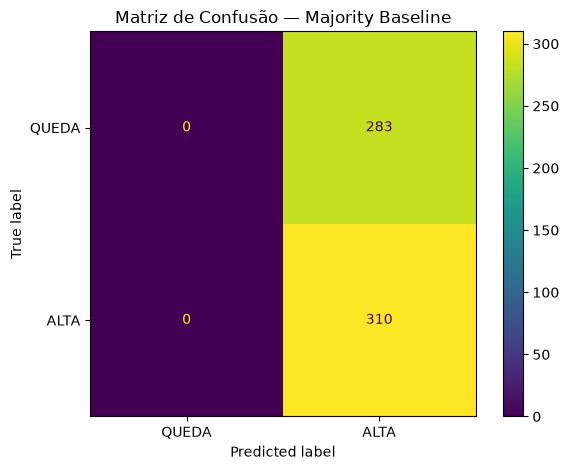

In [161]:
# Avaliação da Majority Baseline
resultado_majority, cm_majority = avaliar_modelo(
    "Majority Baseline",
    y_test,
    y_test_majority
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_majority)
matrizes_confusao.append(cm_majority)

### Segunda Referencia: Persistence Baseline

> A regra que vamos usar para o Persistence Baseline: utilizar a direção observada nos últimos 5 pregões (Retorno_5d) como previsão da direção dos próximos 5 pregões.

O Persistence Baseline tenta ser um pouco mais inteligente que o Majority:
"Vou usar o comportamento mais recente conhecido para fazer minha previsão."

Isso é importante porque queremos responder uma pergunta:
Um modelo de Machine Learning consegue fazer algo melhor do que simplesmente assumir que o comportamento recente continuará?

Avaliação do(a) Persistence Baseline:
{
    "model": "Persistence Baseline",
    "balanced_accuracy": 0.5203921121623163,
    "precision_high": 0.5424836601307189,
    "recall_high": 0.535483870967742,
    "f1_high": 0.538961038961039
}

Matriz de confusão:
[[143 140]
 [144 166]]


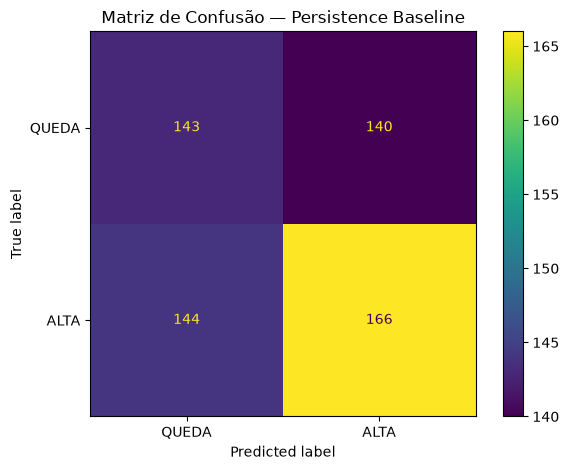

In [162]:
# Aplicação da regra definida para essa baseline
y_test_persistence = (X_test["Retorno_5d"] > 0).astype(int)
y_test_persistence.head(10)

# Avaliação da Persistence Baseline
resultado_persistence, cm_persistence = avaliar_modelo(
    "Persistence Baseline",
    y_test,
    y_test_persistence
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_persistence)
matrizes_confusao.append(cm_persistence)

Até aqui, nossos dois baselines não "aprenderam" nada:

#### Majority - Regra:
Seja qual for a situação → ALTA

#### Persistence - Regra:
Se Retorno_5d > 0 → ALTA
Se Retorno_5d < 0 → QUEDA


Agora vem a mudança de paradigma:

### Primeiro modelo: Regressão Logística

Ele vai receber as sete features:
```
Retorno_Diario
Retorno_5d
Retorno_10d
Media_Retorno_5d
Volatilidade_5d
Variacao_Intradiaria
Amplitude_Diaria
```
tentar aprender uma relação entre essas variáveis e retornar a `Direcao_Futura`

A grande pergunta passa a ser:
> Será que uma combinação dessas informações permite prever melhor os próximos cinco pregões do que nossas duas regras simples?

Avaliação do(a) Logistic Regression:
{
    "model": "Logistic Regression",
    "balanced_accuracy": 0.5089137125270717,
    "precision_high": 0.5274336283185841,
    "recall_high": 0.9612903225806452,
    "f1_high": 0.6811428571428572
}

Matriz de confusão:
[[ 16 267]
 [ 12 298]]


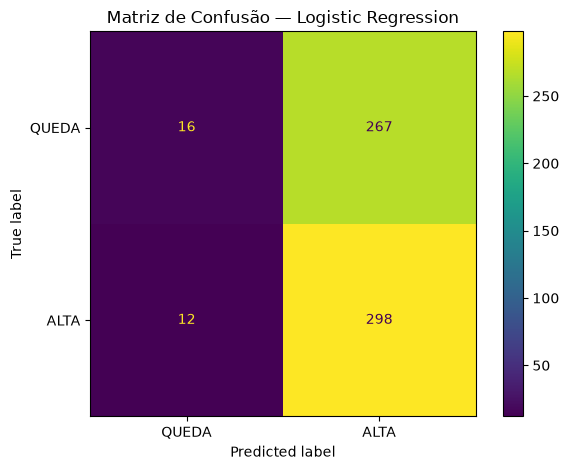

In [163]:
# Criando o scaler, que será usado para converter os valores das features em uma escala comparável
scaler = StandardScaler()

# Cria a escala que será usada em todas as partes do dataset, para evitar vazamento de dados
scaler.fit(X_train)

# Aplica essa escala em cada conjunto de dados
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Criação do modelo
modelo_lr = criar_logistic_regression()

# Onde de fato o modelo começa a aprender
modelo_lr.fit(
    X_train_scaled,
    y_train
)

# A primeira previsão
y_test_lr = modelo_lr.predict(
    X_test_scaled
)

# AVALIACAO DO MODELO
resultado_lr, cm_lr = avaliar_modelo(
    "Logistic Regression",
    y_test,
    y_test_lr
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_lr)
matrizes_confusao.append(cm_lr)

In [164]:
# Depurando o aprendizado do modelo

# Pesos aprendidos pelo modelo
depurar_modelo(
    modelo_lr,
    X_train,
    X_test_scaled,
    "Logistic Regression"
)

Depuração: Logistic Regression

Pesos aprendidos pelo modelo:
             Feature  Coeficiente
      Retorno_Diario    -0.006938
          Retorno_5d    -0.047866
         Retorno_10d     0.169556
    Media_Retorno_5d    -0.044769
     Volatilidade_5d    -0.005308
Variacao_Intradiaria    -0.006299
    Amplitude_Diaria     0.066188

Intercepto:
[0.15022353]

Pesos com maior magnitude:
             Feature  Coeficiente  Importancia_Absoluta
         Retorno_10d     0.169556              0.169556
    Amplitude_Diaria     0.066188              0.066188
          Retorno_5d    -0.047866              0.047866
    Media_Retorno_5d    -0.044769              0.044769
      Retorno_Diario    -0.006938              0.006938
Variacao_Intradiaria    -0.006299              0.006299
     Volatilidade_5d    -0.005308              0.005308

Probabilidades do modelo:
[[0.49045971 0.50954029]
 [0.47313434 0.52686566]
 [0.47707455 0.52292545]
 [0.49197227 0.50802773]
 [0.48944754 0.51055246]
 [0.48995862

Avaliação do(a) Logistic Regression (threshold 55%):
{
    "model": "Logistic Regression (threshold 55%)",
    "balanced_accuracy": 0.5189615866864242,
    "precision_high": 0.5903614457831325,
    "recall_high": 0.15806451612903225,
    "f1_high": 0.24936386768447838
}

Matriz de confusão:
[[249  34]
 [261  49]]


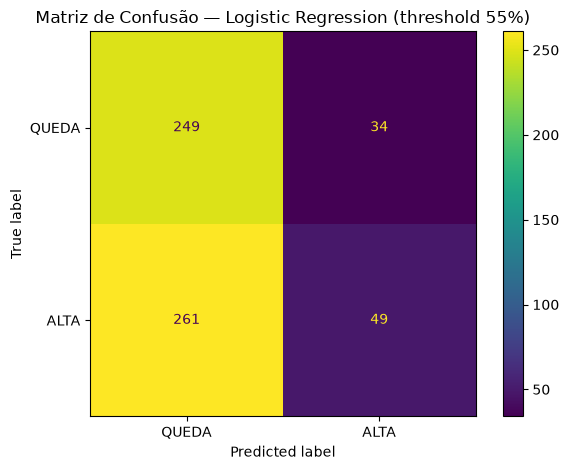

In [165]:
# Experimento com threshold de 55%
threshold = 0.55

# Retornando apenas as probabilidades, para utilizar nessa outra regra de threshold
y_proba = modelo_lr.predict_proba(
    X_test_scaled
)

y_pred_test = (y_proba[:, 1] >= threshold).astype(int)

resultado_lr_55, cm_lr_55 = avaliar_modelo(
    "Logistic Regression (threshold 55%)",
    y_test,
    y_pred_test
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_lr_55)
matrizes_confusao.append(cm_lr_55)

### Segundo modelo: Arvore de Decisão

#### Primeiramente, O que é uma Árvore de Decisão?

A ideia é bem intuitiva. Em vez de calcular uma equação como a Regressão Logística, a árvore cria uma sequência de perguntas sobre as features.

Por exemplo, ela poderia aprender algo parecido com:
```
Retorno_10d > 1,2?
│
├── SIM → Amplitude_Diaria > 2,5?
│          │
│          ├── SIM → ALTA
│          └── NÃO → ALTA
│
└── NÃO → Volatilidade_5d > 1,8?
           │
           ├── SIM → QUEDA
           └── NÃO → QUEDA
```
Esses valores são apenas ilustrativos, não são regras que nossa árvore já aprendeu.

A árvore vai descobrir essas regras sozinha durante o treinamento.


Avaliação do(a) Decision Tree:
{
    "model": "Decision Tree",
    "balanced_accuracy": 0.5060298643565484,
    "precision_high": 0.5288135593220339,
    "recall_high": 0.5032258064516129,
    "f1_high": 0.515702479338843
}

Matriz de confusão:
[[144 139]
 [154 156]]


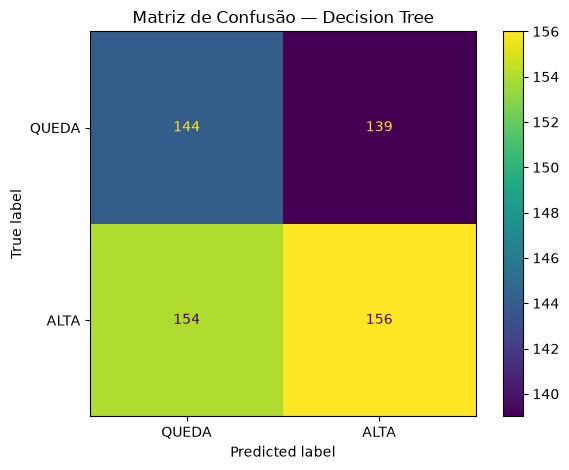

In [166]:
# Criação do modelo
modelo_dt = criar_decision_tree()

# Treinamento do modelo
modelo_dt.fit(X_train, y_train)

# A primeira previsão
y_pred_dt = modelo_dt.predict(X_test)

# Avaliação do modelo
resultado_dt, cm_dt = avaliar_modelo(
    "Decision Tree",
    y_test,
    y_pred_dt
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_dt)
matrizes_confusao.append(cm_dt)

In [167]:
# Depurando o aprendizado do modelo
depurar_modelo(
    modelo_dt,
    X_train,
    X_test,
    "Decision Tree",
    detalhado=False
)

Depuração: Decision Tree

Profundidade da árvore:
27

Quantidade de folhas:
724

Quantidade de nós:
1447

Contribuição das variáveis para a ramificação da árvore:
             Feature  Importancia
    Amplitude_Diaria     0.208044
     Volatilidade_5d     0.207583
         Retorno_10d     0.183286
          Retorno_5d     0.120301
Variacao_Intradiaria     0.099379
    Media_Retorno_5d     0.097672
      Retorno_Diario     0.083735

Probabilidades do modelo:
[[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]



Avaliação do(a) Decision Tree (max_depth=3):
{
    "model": "Decision Tree (max_depth=3)",
    "balanced_accuracy": 0.5549697936851704,
    "precision_high": 0.6009615384615384,
    "recall_high": 0.4032258064516129,
    "f1_high": 0.4826254826254826
}

Matriz de confusão:
[[200  83]
 [185 125]]


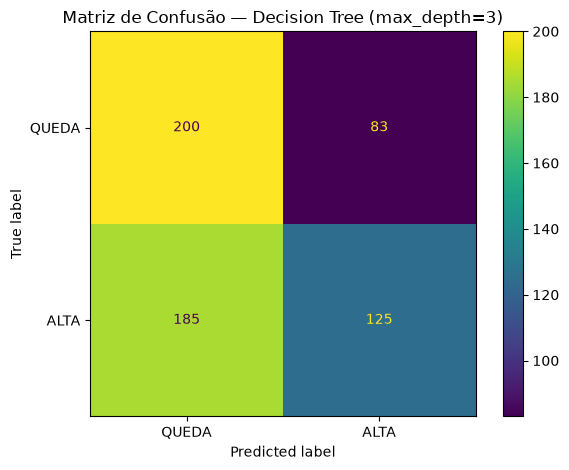


Teste do modelo em 'prod'

Avaliação do(a) Decision Tree Validacao (max_depth=3):
{
    "model": "Decision Tree Validacao (max_depth=3)",
    "balanced_accuracy": 0.5373010340420588,
    "precision_high": 0.5257352941176471,
    "recall_high": 0.5017543859649123,
    "f1_high": 0.5134649910233393
}

Matriz de confusão:
[[173 129]
 [142 143]]


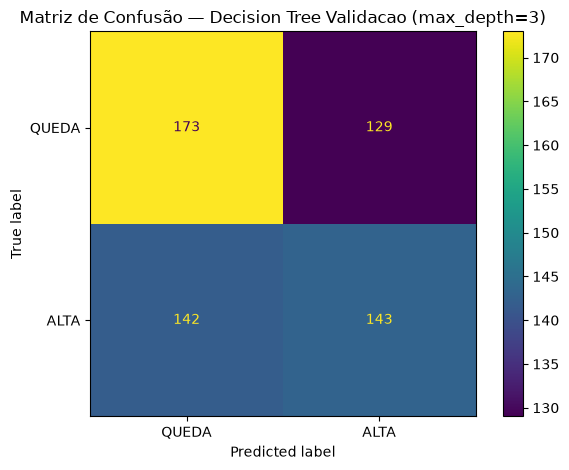

In [182]:
# Criando uma árvore com profundidade limitada para teste
modelo_dt_depth_3 = criar_decision_tree(max_depth=3)

modelo_dt_depth_3.fit(X_train, y_train)

y_pred_dt_depth_3 = modelo_dt_depth_3.predict(X_test)

resultado_dt_depth_3, cm_dt_depth_3 = avaliar_modelo(
    "Decision Tree (max_depth=3)",
    y_test,
    y_pred_dt_depth_3
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_dt_depth_3)
matrizes_confusao.append(cm_dt_depth_3)

y_pred_dt_val_test = modelo_dt_depth_3.predict(X_val)

print("\nTeste do modelo em 'prod'\n")
resultado_prod = avaliar_modelo(
    "Decision Tree Validacao (max_depth=3)",
    y_val,
    y_pred_dt_val_test
)

Depuração: Decision Tree (max_depth=3)

Profundidade da árvore:
3

Quantidade de folhas:
8

Quantidade de nós:
15

Contribuição das variáveis para a ramificação da árvore:
             Feature  Importancia
         Retorno_10d     0.453231
    Media_Retorno_5d     0.226411
    Amplitude_Diaria     0.200325
          Retorno_5d     0.120033
      Retorno_Diario     0.000000
     Volatilidade_5d     0.000000
Variacao_Intradiaria     0.000000

Probabilidades do modelo:
[[0.50742358 0.49257642]
 [0.50742358 0.49257642]
 [0.50742358 0.49257642]
 [0.50742358 0.49257642]
 [0.50742358 0.49257642]
 [0.50742358 0.49257642]
 [0.50742358 0.49257642]
 [0.50742358 0.49257642]
 [0.50742358 0.49257642]
 [0.50742358 0.49257642]]

Regras da árvore:
|--- Retorno_10d <= 1.58
|   |--- Amplitude_Diaria <= 2.52
|   |   |--- Retorno_10d <= 0.89
|   |   |   |--- class: 0
|   |   |--- Retorno_10d >  0.89
|   |   |   |--- class: 0
|   |--- Amplitude_Diaria >  2.52
|   |   |--- Media_Retorno_5d <= -0.21
|   |   |

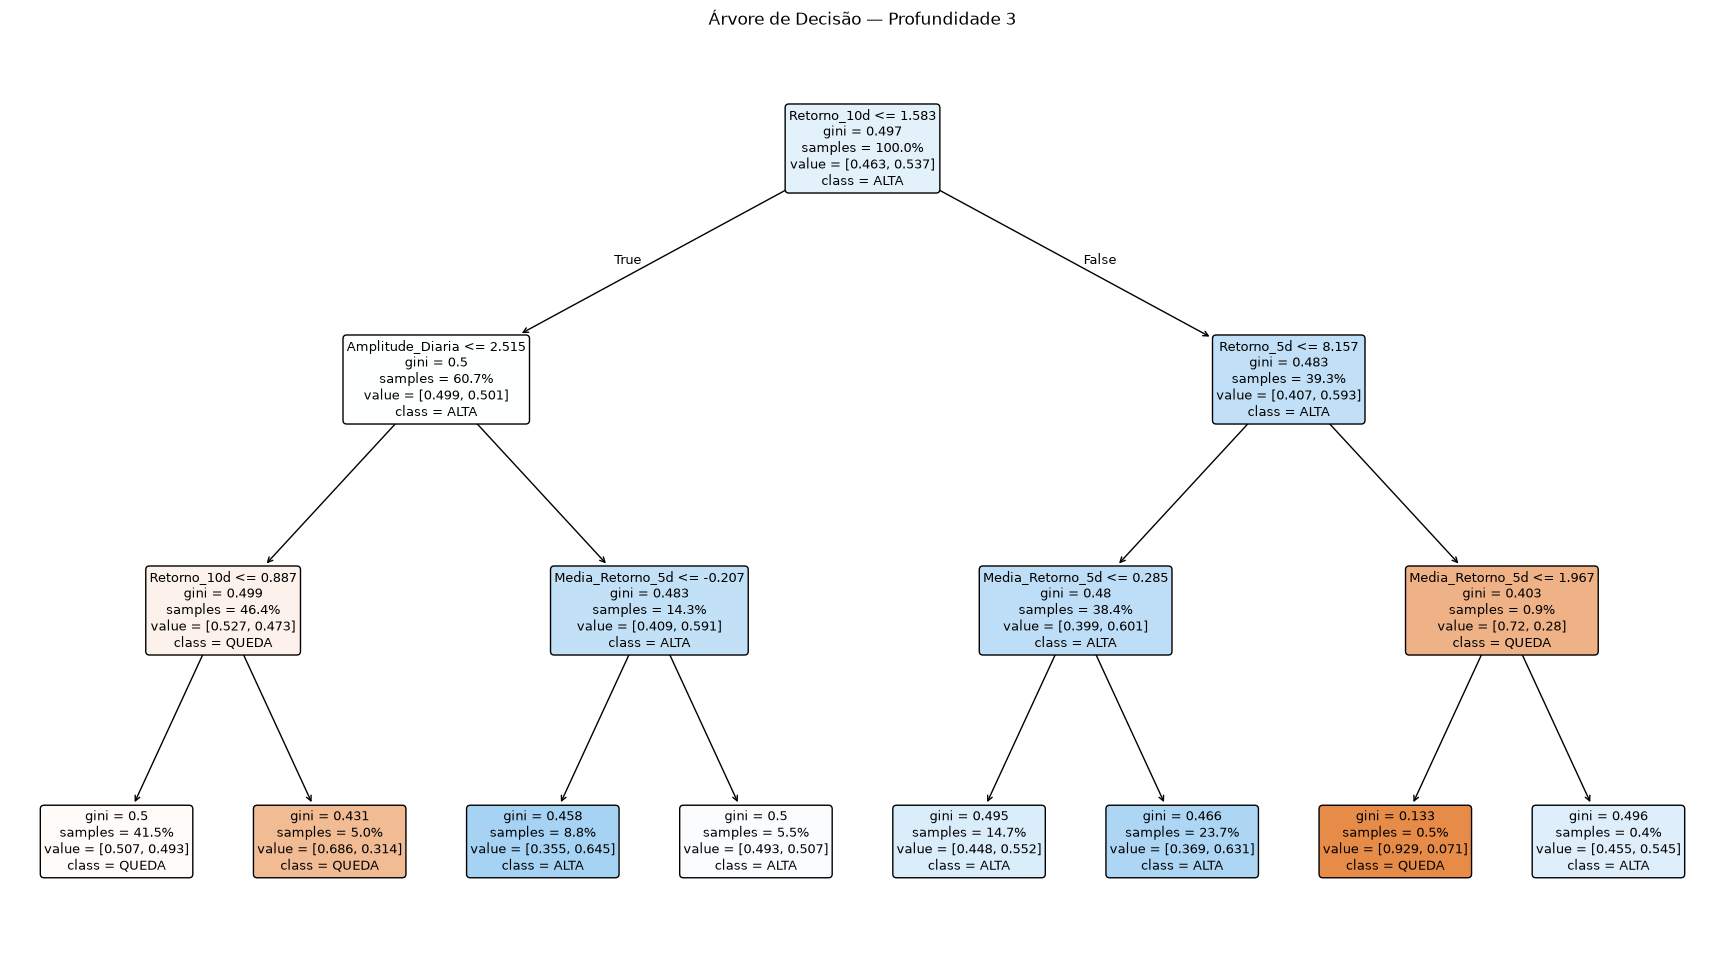

In [187]:
# Depurando o aprendizado do modelo
depurar_modelo(
    modelo_dt_depth_3,
    X_train,
    X_test,
    "Decision Tree (max_depth=3)",
    detalhado=True
)

plt.figure(figsize=(22, 12))

plot_tree(
    modelo_dt_depth_3,
    feature_names=X_train.columns,
    class_names=["QUEDA", "ALTA"],
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=9
)

plt.title("Árvore de Decisão — Profundidade 3")
plt.show()

### Terceiro modelo: Random Forest

#### Primeiramente, O que é o Random Forest?

Você já sabe como funciona uma Árvore de Decisão:
> Ela cria uma sequência de perguntas sobre as características dos dados até chegar a uma decisão: ALTA ou QUEDA.

O problema é que uma única árvore pode ficar muito dependente dos dados de treinamento.

O Random Forest tenta resolver isso criando várias árvores de decisão e combinando suas previsões.

Imagine, simplificando, que criamos 100 árvores:
```
Árvore 1  → ALTA
Árvore 2  → QUEDA
Árvore 3  → ALTA
Árvore 4  → ALTA
...
```
Árvore 100 → QUEDA

Depois fazemos uma espécie de votação:
```
ALTA  → 58 árvores
QUEDA → 42 árvores
```

Resultado final:
ALTA

É daí que vem o nome Random Forest: **uma "floresta" de várias árvores**.

Avaliação do(a) Random Forest:
{
    "model": "Random Forest",
    "balanced_accuracy": 0.5316026444773738,
    "precision_high": 0.5505952380952381,
    "recall_high": 0.5967741935483871,
    "f1_high": 0.5727554179566563
}

Matriz de confusão:
[[132 151]
 [125 185]]


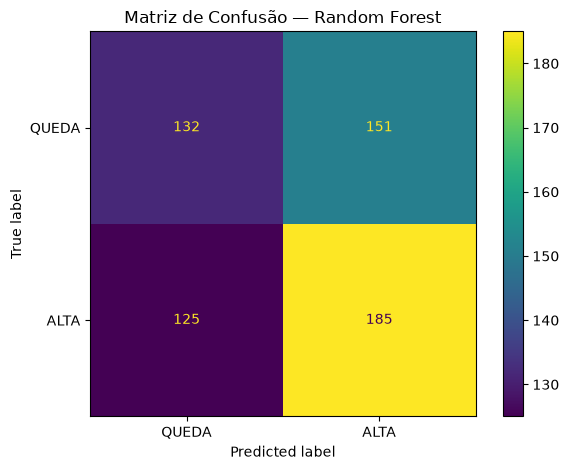

In [169]:
# Criando o modelo
modelo_rf = criar_random_forest()

# Treinamento do modelo
modelo_rf.fit(X_train, y_train)

# Fazer as previsões
y_pred_rf = modelo_rf.predict(X_test)

# Avaliação do modelo
resultado_rf, cm_rf = avaliar_modelo(
    "Random Forest",
    y_test,
    y_pred_rf
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_rf)
matrizes_confusao.append(cm_rf)

In [170]:
depurar_modelo(
    modelo_rf,
    X_train,
    X_test,
    "Random Forest",
    detalhado=False
)

Depuração: Random Forest

Quantidade de árvores:
100

Profundidade média:
28.36

Menor profundidade:
22

Maior profundidade:
50

Importância das variáveis para a ramificação das árvores:
             Feature  Importancia
         Retorno_10d     0.162889
     Volatilidade_5d     0.156655
    Amplitude_Diaria     0.145421
          Retorno_5d     0.137193
    Media_Retorno_5d     0.135958
      Retorno_Diario     0.131587
Variacao_Intradiaria     0.130297

Probabilidades do modelo:
[[0.7  0.3 ]
 [0.47 0.53]
 [0.32 0.68]
 [0.55 0.45]
 [0.55 0.45]
 [0.54 0.46]
 [0.44 0.56]
 [0.47 0.53]
 [0.6  0.4 ]
 [0.45 0.55]]

Informações da primeira árvore:
Profundidade: 32
Quantidade de folhas: 608



Avaliação do(a) Random Forest (max_depth=3):
{
    "model": "Random Forest (max_depth=3)",
    "balanced_accuracy": 0.5133990653140317,
    "precision_high": 0.5347432024169184,
    "recall_high": 0.5709677419354838,
    "f1_high": 0.5522620904836193
}

Matriz de confusão:
[[129 154]
 [133 177]]


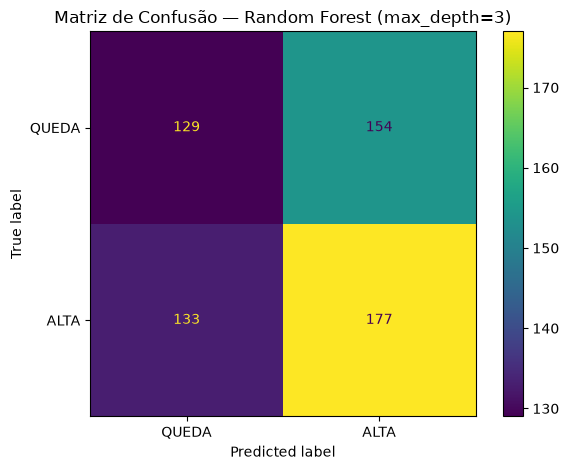

In [171]:
# Avaliação do Modelo 3.1: Random Forest com max_depth=3:
modelo_rf_depth_3 = criar_random_forest(max_depth=3)

modelo_rf_depth_3.fit(X_train, y_train)

y_pred_rf_depth_3 = modelo_rf_depth_3.predict(X_test)

resultado_rf_depth_3, cm_rf_depth_3 = avaliar_modelo(
    "Random Forest (max_depth=3)",
    y_test,
    y_pred_rf_depth3
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_rf_depth_3)
matrizes_confusao.append(cm_rf_depth_3)

### Início dos Experimentos

Nossa métrica principal continuará sendo a **Balanced Accuracy**.

Ela é especialmente interessante porque considera o desempenho nas duas classes (ALTA e QUEDA), evitando que um modelo pareça bom apenas por favorecer uma delas.

O processo será:
```
1. Treinamento: Utilizar a base de treinamento para encontrar boas configurações, com validação cruzada temporal.

2. Validação: Avaliar as melhores configurações em um período cronológico que não participou do treinamento.

3. Comparação: Comparar os resultados com os modelos padrão e com os experimentos anteriores.

4. Teste final: Utilizar a base de teste somente na avaliação final, depois de escolher as configurações.
```

Vamos utilizar o GridSearchCV, que testa automaticamente diferentes combinações de parâmetros.

E, como nossos dados são séries temporais, vamos utilizar o TimeSeriesSplit, em vez de uma validação cruzada aleatória.

Isso é importante: não queremos treinar com dados de um período futuro e validar com dados de um período passado.

### Primeiro Experimento: Árvore de Decisão.

Ela é mais simples de interpretar e já tivemos um resultado interessante: limitar sua profundidade a 3 elevou a Balanced Accuracy de aproximadamente 0,529 para 0,555 no teste que realizamos.

Vamos investigar outros parâmetros:
| Parâmetro | O que controla? |
|---|---|
| max_depth | Profundidade máxima da árvore |
| min_samples_split | Mínimo de amostras necessário para dividir um nó |
| min_samples_leaf | Mínimo de amostras permitido em uma folha|
| class_weight | Peso atribuído às classes durante o aprendizado|

A hipótese é que árvores menos complexas e com folhas mais bem representadas possam generalizar melhor.

In [16]:
# Preparação da base usada nas experimentações
# Definindo a validação cruzada
validacao_temporal = TimeSeriesSplit(
    n_splits=5,
    gap=5
)

# Diretório raiz do projeto
ROOT_DIR = Path.cwd()

# Diretório de resultados
RESULTS_DIR = ROOT_DIR / "reports" / "experiments"

# Criar diretório caso não exista
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [188]:
# Definição das combinações de parâmetros que vamos testar
parametros_dt = {
    "max_depth": [None, 2, 3, 4, 5, 8, 10],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_leaf_nodes": [None, 4, 6, 8, 12, 16],
    "criterion": ["gini", "entropy", "log_loss"],
    "ccp_alpha": [0.0, 0.0001, 0.001, 0.005, 0.01],
    "min_impurity_decrease": [0.0, 0.0001, 0.001, 0.005],
    "max_features": [None, "sqrt", "log2", 0.8]
}

# Executando a busca
modelo_base_dt = criar_decision_tree()
busca_arvore = GridSearchCV(
    estimator=modelo_base_dt,
    param_grid=parametros_dt,
    scoring="balanced_accuracy",
    cv=validacao_temporal,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=False,
    pre_dispatch="2*n_jobs"
)
busca_arvore.fit(X_train, y_train)

print("\nQuantidade de combinações testadas:")
print(len(busca_arvore.cv_results_["params"]))

# Analisando os resultados
print("Melhores parâmetros:")
print(busca_arvore.best_params_)

print("\nMelhor Balanced Accuracy média:")
print(busca_arvore.best_score_)

caminho_dt = RESULTS_DIR / "resultados_decision_tree_grid_search.csv"

# Visualizar as 10 melhores combinações
resultados_dt_completos = pd.DataFrame(
    busca_arvore.cv_results_
)

resultados_dt_completos = resultados_dt_completos.sort_values(
    by="mean_test_score",
    ascending=False
)

colunas = [
    "mean_test_score",
    "std_test_score",
    "params"
]

display(
    resultados_dt_completos[colunas].head(20)
)

resultados_dt_completos.to_csv(
    caminho_dt,
    index=False,
    encoding="utf-8-sig"
)
print(f"Resultados salvos em: {caminho_dt}")

Fitting 5 folds for each of 50400 candidates, totalling 252000 fits


KeyboardInterrupt: 

Avaliação do(a) Decision Tree Otimizada (Base validação):
{
    "model": "Decision Tree Otimizada (Base validação)",
    "balanced_accuracy": 0.5415998605785988,
    "precision_high": 0.5275862068965518,
    "recall_high": 0.5368421052631579,
    "f1_high": 0.5321739130434783
}

Matriz de confusão:
[[165 137]
 [132 153]]


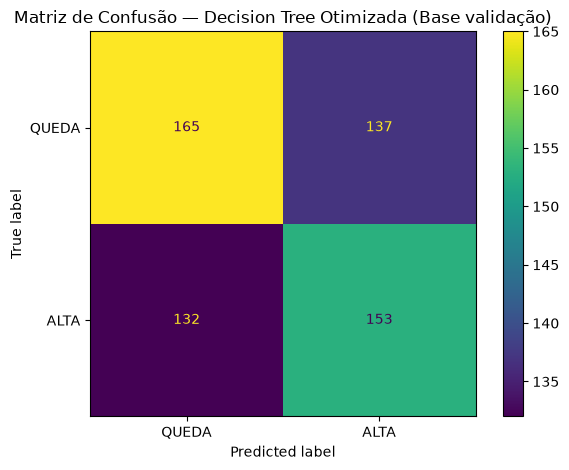

In [174]:
# Avaliando o modelo com a melhor combinação encontrada
melhor_arvore = busca_arvore.best_estimator_

y_pred_arvore_val = melhor_arvore.predict(X_val)

resultado_arvore_otimizada, cm_arvore_otimizada = avaliar_modelo(
    "Decision Tree Otimizada - Busca Exaustiva",
    y_val,
    y_pred_arvore_val
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_arvore_otimizada)
matrizes_confusao.append(cm_arvore_otimizada)

Avaliação do(a) Decision Tree Default (Base Validação):
{
    "model": "Decision Tree Default (Base Validação)",
    "balanced_accuracy": 0.5213372836063669,
    "precision_high": 0.5068027210884354,
    "recall_high": 0.5228070175438596,
    "f1_high": 0.5146804835924007
}

Matriz de confusão:
[[157 145]
 [136 149]]


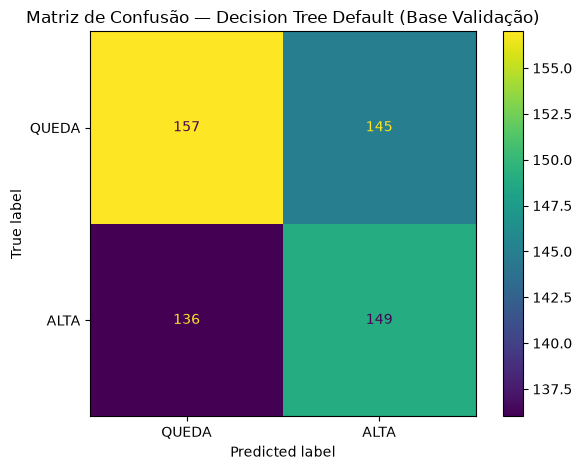

In [176]:
# Testando decision tree default com a base de validação
modelo_dt_default = criar_decision_tree()

modelo_dt_default.fit(X_train, y_train)

y_pred_dt_val = modelo_dt_default.predict(X_val)

resultado_dt_val, cm_dt_val = avaliar_modelo(
    "Decision Tree Default (Base Validação)",
    y_val,
    y_pred_dt_val
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_dt_val)
matrizes_confusao.append(cm_dt_val)

In [13]:
# Definição das combinações de parâmetros que vamos testar
parametros_comuns_rf = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 3, 5, 8, 12, 20],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": ["sqrt", "log2", 0.5, 0.8, 1.0],
    "criterion": ["gini", "entropy", "log_loss"],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "ccp_alpha": [0.0, 0.0001, 0.001, 0.005, 0.01],
    "max_leaf_nodes": [None, 8, 16, 32, 64]
}

# Grades condicionais:
# bootstrap=True permite testar diferentes max_samples
# bootstrap=False exige max_samples=None
parametros_rf = [
    {
        **parametros_comuns_rf,
        "bootstrap": [True],
        "max_samples": [None, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    },
    {
        **parametros_comuns_rf,
        "bootstrap": [False],
        "max_samples": [None]
    }
]

# Modelo base
modelo_base_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)
# Busca pelos melhores parâmetros
busca_rf = RandomizedSearchCV(
    estimator=modelo_base_rf,
    param_distributions=parametros_rf,
    n_iter=500,
    scoring="balanced_accuracy",
    cv=validacao_temporal,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=False,
    pre_dispatch="2*n_jobs"
)
busca_rf.fit(X_train, y_train)

print("\nCombinações avaliadas:")
print(len(busca_rf.cv_results_["params"]))

print("Melhores parâmetros:")
print(busca_rf.best_params_)

print("\nMelhor Balanced Accuracy na validação cruzada:")
print(busca_rf.best_score_)

caminho_rf = RESULTS_DIR / "resultados_random_forest_busca_ampliada.csv"

resultados_rf_completos = pd.DataFrame(
    busca_rf.cv_results_
)

resultados_rf_completos = resultados_rf_completos.sort_values(
    by="mean_test_score",
    ascending=False
)

colunas = [
    "mean_test_score",
    "std_test_score",
    "params"
]

display(
    resultados_rf_completos[colunas].head(20)
)

resultados_rf_completos.to_csv(
    caminho_rf,
    index=False,
    encoding="utf-8-sig"
)

print(f"Resultados salvos em: {caminho_rf}")


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Melhores parâmetros:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_samples': 1.0, 'max_leaf_nodes': 32, 'max_features': 'sqrt', 'max_depth': 8, 'criterion': 'gini', 'class_weight': 'balanced_subsample', 'ccp_alpha': 0.005}

Melhor Balanced Accuracy na validação cruzada:
0.5295477003905024


Avaliação do(a) Random Forest Otimizado (Base Validação):
{
    "model": "Random Forest Otimizado (Base Validação)",
    "balanced_accuracy": 0.5331706750319507,
    "precision_high": 0.5124653739612188,
    "recall_high": 0.6491228070175439,
    "f1_high": 0.5727554179566563
}

Matriz de confusão:
[[126 176]
 [100 185]]


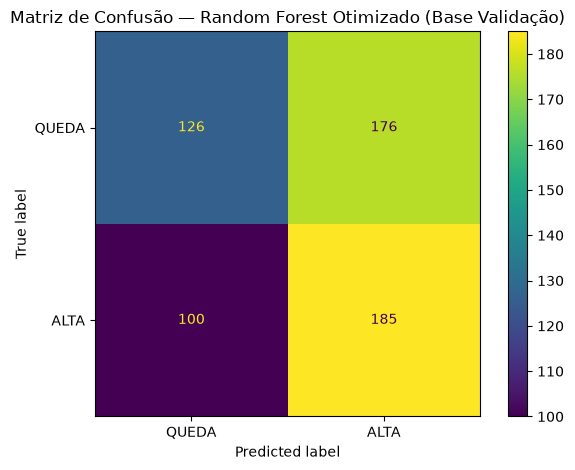

In [178]:
# Melhor modelo encontrado
melhor_rf = busca_rf.best_estimator_

# Previsões na validação
y_pred_rf_otimizado = melhor_rf.predict(X_val)

# Avaliação
resultado_rf_otimizada, cm_rf_otimizada = avaliar_modelo(
    nome_modelo="Random Forest Otimizada - Busca Exaustiva",
    y_true=y_val,
    y_pred=y_pred_rf_otimizado
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_rf_otimizada)
matrizes_confusao.append(cm_rf_otimizada)

Avaliação do(a) Random Forest Default (Base Validação):
{
    "model": "Random Forest Default (Base Validação)",
    "balanced_accuracy": 0.5281805507145346,
    "precision_high": 0.5106382978723404,
    "recall_high": 0.5894736842105263,
    "f1_high": 0.5472312703583062
}

Matriz de confusão:
[[141 161]
 [117 168]]


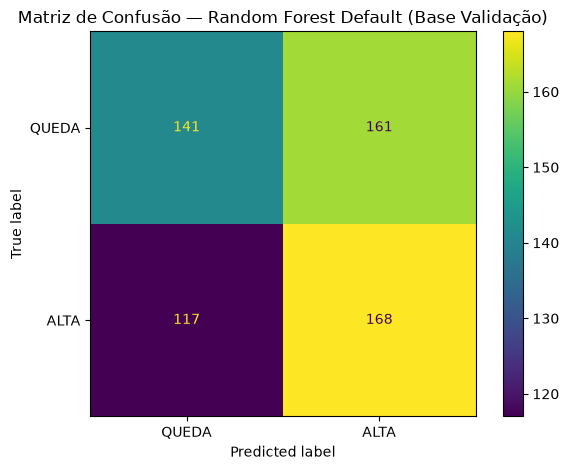

In [179]:
# Testando a base de validação com o random forest default
modelo_rf_default = criar_random_forest()

modelo_rf_default.fit(X_train, y_train)

y_pred_rf_val = modelo_rf_default.predict(X_val)

resultado_rf_val, cm_rf_val = avaliar_modelo(
    nome_modelo="Random Forest Default (Base Validação)",
    y_true=y_val,
    y_pred=y_pred_rf_val
)

# Jogando os resultados no array de resultados
resultados_modelos.append(resultado_rf_val)
matrizes_confusao.append(cm_rf_val)

In [180]:
# Printando os resultados até então:
for i in range(len(resultados_modelos)):
    print(f"Resultados modelo {resultados_modelos[i]["model"]}:")
    print(json.dumps(
        resultados_modelos[i],
        ensure_ascii=False,
        indent=4
    ))
    print(matrizes_confusao[i], "\n")

Resultados modelo Majority Baseline:
{
    "model": "Majority Baseline",
    "balanced_accuracy": 0.5,
    "precision_high": 0.5227655986509275,
    "recall_high": 1.0,
    "f1_high": 0.6866002214839424
}
[[  0 283]
 [  0 310]] 

Resultados modelo Persistence Baseline:
{
    "model": "Persistence Baseline",
    "balanced_accuracy": 0.5203921121623163,
    "precision_high": 0.5424836601307189,
    "recall_high": 0.535483870967742,
    "f1_high": 0.538961038961039
}
[[143 140]
 [144 166]] 

Resultados modelo Logistic Regression:
{
    "model": "Logistic Regression",
    "balanced_accuracy": 0.5089137125270717,
    "precision_high": 0.5274336283185841,
    "recall_high": 0.9612903225806452,
    "f1_high": 0.6811428571428572
}
[[ 16 267]
 [ 12 298]] 

Resultados modelo Logistic Regression (threshold 55%):
{
    "model": "Logistic Regression (threshold 55%)",
    "balanced_accuracy": 0.5189615866864242,
    "precision_high": 0.5903614457831325,
    "recall_high": 0.15806451612903225,
    "f